In [9]:
# Open Gym Environment
import gym
import gym_mppt

# # Check Gym Environments
# from gym import envs
# all_envs = envs.registry
# for key, value in sorted(all_envs.items(), key=lambda x: x[0]): 
#     print(key)

In [10]:
problem = 'mppt_shaded-v2'
env = gym.make(problem)

num_states = env.observation_space.shape[0]
print("Size of State Space ->  {}".format(num_states))
num_actions = env.action_space.shape[0]
print("Size of Action Space ->  {}".format(num_actions))

upper_bound = env.action_space.high[0]
lower_bound = env.action_space.low[0]

print("Max Value of Action ->  {}".format(upper_bound))
print("Min Value of Action ->  {}".format(lower_bound))

Size of State Space ->  3
Size of Action Space ->  1
Max Value of Action ->  15.0
Min Value of Action ->  -15.0


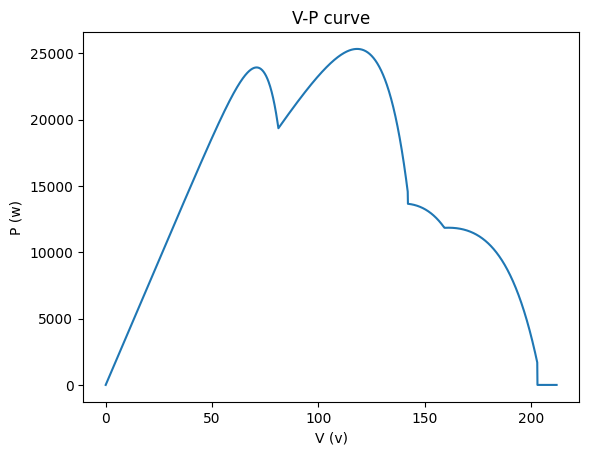

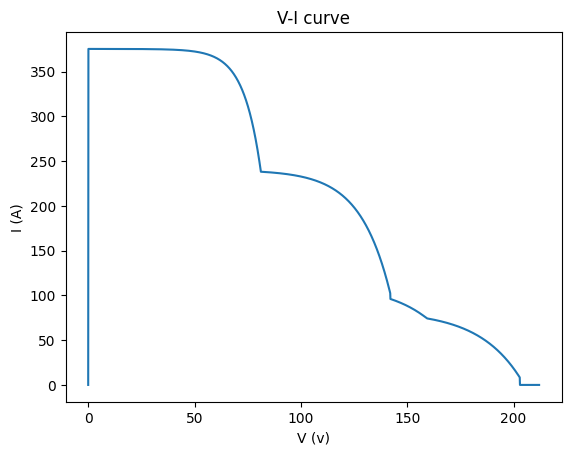

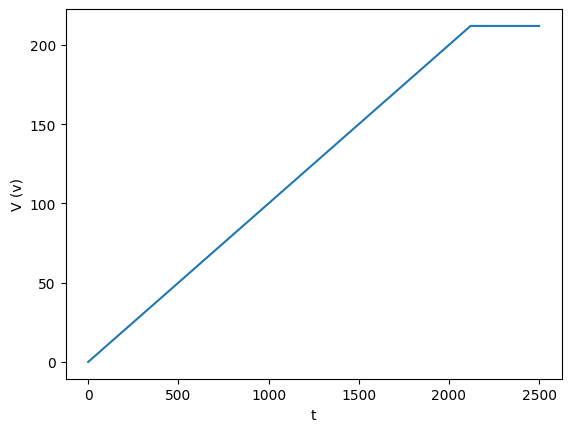

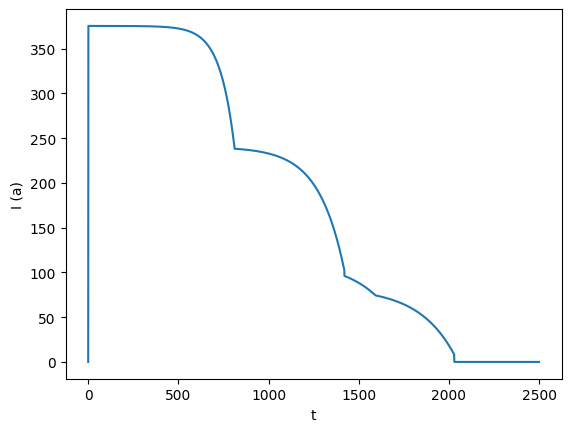

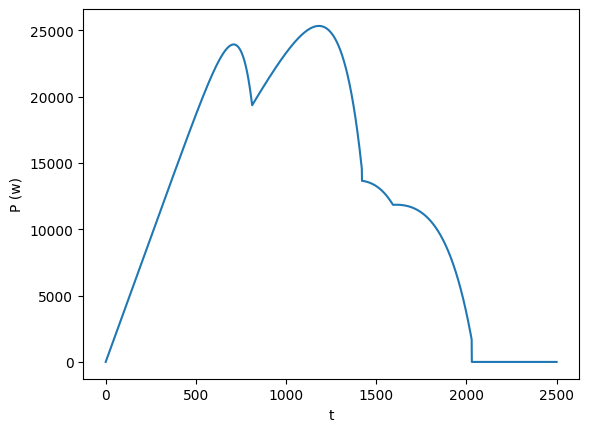

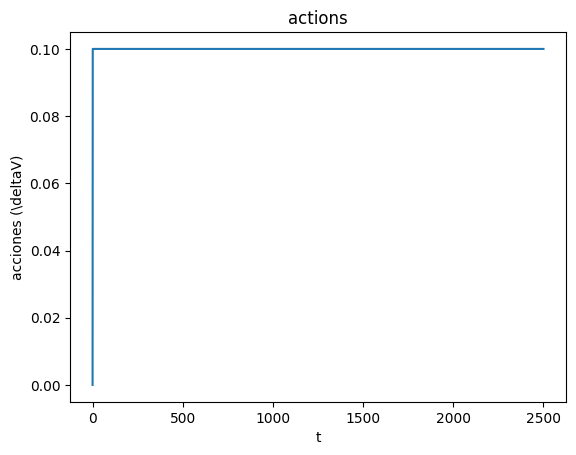

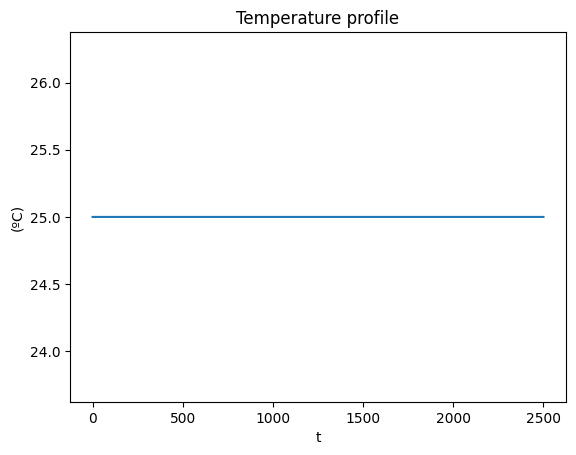

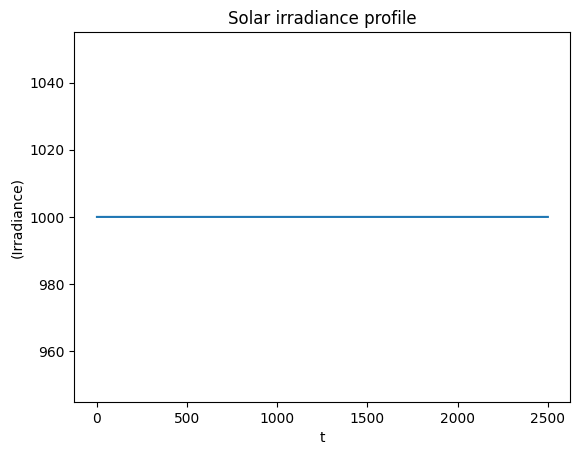

In [11]:
%run Graphs.ipynb
import warnings
warnings.filterwarnings('ignore')

observation = env.reset()
# print(observation)

irradiances = list([1000.])
temperatures = list([25.])
# [a, 10, b, 10, c, 10]
sh = list([[4, 10, 7, 10, 10, 10]])

max_steps = 2500
# min_action = -5.
# max_action = 5.

observation = env.setTempIrr(observation, temperatures[0], irradiances[0], sh[0])
# data = DATA(observation, temperatures[0], irradiances[0])
data = [0] * len(temperatures)

for i in range(len(temperatures)):
    #observation =  env.reset()
    observation = env.reset()
    env.setTempIrr(observation, temperatures[i], irradiances[i], sh[i])
    data[i] = DATA(observation, temperatures[i], irradiances[i])
   
    for j in range(max_steps):
#         tf_observation = tf.expand_dims(tf.convert_to_tensor(observation), 0)    
        action = 0.1
#         action = policy(tf_observation, ou_noise)
#         action = np.clip(action,min_action,max_action)
#         print(action)

        observation, reward, done, info = env.step(action, 1)
        data[i].add(observation[0], observation[1], observation[2], info['Corriente'], info['Temperatura'], info['Irradiancia'], info['Accion'])

    data[i].plotear()
#     print('iteration', i)
#     plt.plot(data[i].V, data[i].P)
#     plt.xlabel('V (v)')
#     plt.ylabel('P (w)')
#     plt.title('V-P curve')
#     plt.show()
    
# print(data)

In [12]:
max(data[0].P)

25321.874255218165

In [13]:
for i in range(len(data[0].P)):
    print(i, data[0].P[i])

0 0.0
1 37.547266687538446
2 75.09451097200368
3 112.64173251583846
4 150.18893097654131
5 187.73610600659472
6 225.28325725339198
7 262.83038435916285
8 300.37748696089875
9 337.9245646902761
10 375.47161717357943
11 413.01864403162216
12 450.5656448796676
13 488.1126193273478
14 525.6595669785818
15 563.2064874314923
16 600.7533802783214
17 638.3002451053449
18 675.8470814927854
19 713.3938890147248
20 750.9406672390143
21 788.4874157271839
22 826.0341340343512
23 863.5808217091264
24 901.1274782935193
25 938.6741033228432
26 976.2206963256159
27 1013.7672568234631
28 1051.313784331017
29 1088.8602783558138
30 1126.4067383981926
31 1163.9531639511895
32 1201.4995545004308
33 1239.0459095240271
34 1276.5922284924625
35 1314.1385108684856
36 1351.6847561069937
37 1389.2309636549228
38 1426.7771329511293
39 1464.3232634262743
40 1501.8693545027015
41 1539.415405594321
42 1576.9614161064837
43 1614.5073854358577
44 1652.053312970301
45 1689.5991980887366
46 1727.1450401610202
47 1764.690

In [14]:
max(data[0].V)

212.0